# Gamma oscillations

Gamma-band responses adapted versions of the `duecker_ET_model` to a proximal Poisson drive.

| Manuscript figure | Section |
| --- | --- |
| Fig. 11b–g | Sustained gamma (50 Hz) |
| Fig. 11h–k | Bursty gamma |
| Supp. Fig. 4 | Poisson drive to the `duecker_ET_model` |

Panels are defined individually as `plot_<panel>(ax, ...)` and reassembled by
`plot_single_trial_sim` / `plot_multi_trial_sim`, so the standalone panels and the
composites cannot drift apart. Figures are written to `results/network_sim/gamma/`.

Author: Katharina Duecker <katharina.duecker@gmail.com>


In [1]:
# ONLY RUN IF USING MPI ON OSCAR
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin:/Users/katharinaduecker/.local/bin:/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin:/Users/katharinaduecker/miniconda3/condabin:/opt/homebrew/bin:/opt/homebrew/sbin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/appleinternal/bin:/pkg/env/global/bin:/opt/X11/bin:/Library/Apple/usr/bin:/Library/TeX/texbin
Which mpiexec:
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin/mpiexec



In [2]:
import os
import os.path as op

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.signal import periodogram

import hnn_core
from hnn_core import (duecker_ET_model, simulate_dipole, average_dipoles,
                      MPIBackend, JoblibBackend,
                      write_network_configuration, read_network_configuration)
from hnn_core.externals.mne import tfr_array_morlet

from hnn_tuning import NETWORK_SIM, results_dir, RESULTS
from hnn_tuning.plot_utils import add_scalebar

# --- paths ---
CONFIG_ROOT = op.join(NETWORK_SIM, 'network_configs')
pathfig = results_dir('network_sim', 'gamma')

# --- simulation / plotting settings ---
n_procs = 3
mpl.rcParams['pdf.fonttype'] = 42

# apical sections and their colours, per pyramidal cell type
SECTIONS = {
    'L2_pyramidal': ['soma', 'apical_trunk', 'apical_1', 'apical_tuft'],
    'L5_pyramidal': ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft'],
}
SECTION_COLORS = {
    'L2_pyramidal': ['#110308', '#420d20', '#741638', '#a52050'],
    'L5_pyramidal': ['k', '#2A3760', '#36477B', '#425796', '#5C72B7'],
}
# gid range used to pick the most-active example cell of each type
GID_RANGE = {'L2_pyramidal': (35, 135), 'L5_pyramidal': (170, 270)}

XTICKS = np.arange(0, 1001, 250)

# dipoles are scaled FOR PLOTTING ONLY, so that overlay_dipoles renders them at a
# visible amplitude on the spike raster (plot_raster scales a copy internally)
DPL_PLOT_SCALE = 5000

In [19]:
pathfig

PosixPath('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/results/network_sim/gamma')

## Helpers

In [3]:
def _nice_ylim(y_max):
    """(upper, ticks) for axis from 0 to just above y_max.

    Rounds up to first significant digit. 3 ticks if that digit is even,
    4 if odd.
    """
    if not np.isfinite(y_max) or y_max <= 0:
        return 1.0, np.linspace(0, 1, 4)
    order = np.floor(np.log10(y_max))
    leading = int(np.ceil(y_max / 10**order))
    upper = leading * 10**order
    n_ticks = 3 if leading % 2 == 0 else 4
    return upper, np.linspace(0, upper, n_ticks)


def _example_gid(net, cell_type):
    """gid of the most-active cell of `cell_type` in trial 0."""
    lo, hi = GID_RANGE[cell_type]
    gids = np.array(net.cell_response.spike_gids[0])
    gids = gids[(gids >= lo) & (gids < hi)]
    unique, counts = np.unique(gids, return_counts=True)
    return unique[np.argmax(counts)]


def _compute_tfr(dpl, freqs, average_trials=False):
    """Morlet power for the aggregate dipole; single trial or trial-averaged."""
    trials = dpl if average_trials else [dpl[0]]
    tfr = np.zeros((len(trials), len(freqs), len(trials[0].times)))
    for i, d in enumerate(trials):
        tfr[i] = tfr_array_morlet(d.data['agg'][None, None, :], d.sfreq,
                                  freqs, output='power').squeeze()
    return tfr.mean(axis=0)

## Fig. 11b–g — sustained gamma (50 Hz)

Strong, fast (rate 200 Hz) proximal Poisson drive; single trial, composite via `plot_single_trial_sim`.

In [4]:
network_fname = op.join(CONFIG_ROOT, 'duecker_ET_gamma_50Hz_sustained')
net = read_network_configuration(network_fname)

#with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
dpl = simulate_dipole(net, tstop=1000, bsl_cor='duecker', n_trials=1,
                    record_ca='all', record_vsec='all')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Trial 1: 360.

## Panel functions

One panel per cell: each defines its `plot_<panel>(ax, ...)` function and renders it standalone on the sustained-gamma run above. The composites below reassemble these same functions.

<Axes: label='Spike histogram', ylabel='Counts'>

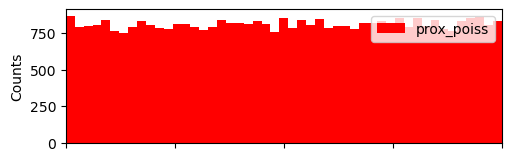

In [5]:
def plot_drive_hist(ax, net, trial_idx=0):
    """Histogram of the Poisson drive spikes (drive/input types only)."""
    net.cell_response.plot_spikes_hist(ax=ax, show=False, trial_idx=trial_idx)
    ax.set_xlim([0, 1000])
    ax.set_xticks(XTICKS)
    ax.set_xticklabels([])
    ax.set_xlabel('')
    return ax

fig, ax = plt.subplots(figsize=(5, 1.5), constrained_layout=True)
plot_drive_hist(ax, net)

<Axes: xlabel='time (ms)', ylabel='dipole (nA·m)'>

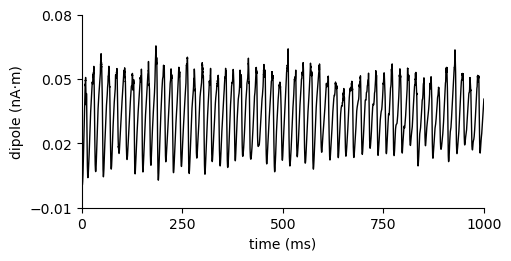

In [6]:
def plot_dipole(ax, dpl, key='agg', pad=0.01):
    """Aggregate (or layer) dipole waveform, with limits padded around the data."""
    y = dpl[0].data[key]
    ax.plot(dpl[0].times, y, color='k', linewidth=1)
    ax.set_ylabel('dipole (nA\u00b7m)')
    ax.set_xlabel('time (ms)')
    ax.set_xlim([0, 1000])
    ax.set_xticks(XTICKS)
    lo, hi = np.round(y.min() - pad, 2), np.round(y.max() + pad, 2)
    ax.set_ylim([lo, hi])
    ax.set_yticks(np.linspace(lo, hi, 4))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return ax

fig, ax = plt.subplots(figsize=(5, 2.5), constrained_layout=True)
plot_dipole(ax, dpl)

<Axes: xlabel='time (ms)', ylabel='neuron index'>

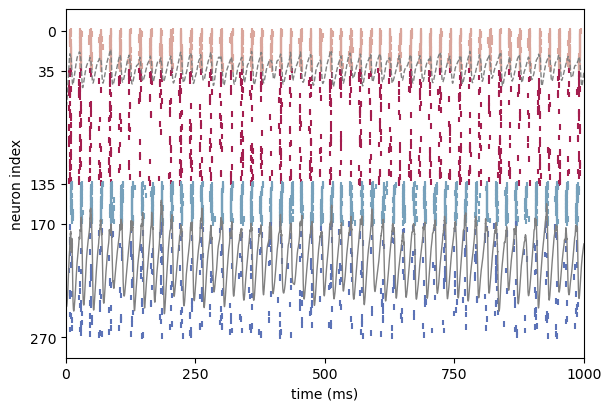

In [7]:
def plot_raster(ax, net, dpl, trial_idx=0, scale_factor=None):
    """Spike raster for all cell types with the L2/L5 dipoles overlaid (as in the ERP figure).

    The dipoles are scaled by `scale_factor` for plotting only: `overlay_dipoles`
    rescales them to the raster extent, and unscaled gamma dipoles are too small to
    read. `Dipole.scale` works in place, so we scale COPIES and never touch `dpl`.
    """
    scale_factor = DPL_PLOT_SCALE if scale_factor is None else scale_factor
    dpl_plot = dpl[0].copy().scale(scale_factor)
    net.cell_response.plot_spikes_raster(
        ax=ax, dpl=dpl_plot, overlay_dipoles=True, show=False, show_legend=False,
        yticks=[0, 35, 135, 170, 270], ylabel='neuron index', title='', trial_idx=trial_idx)
    ax.set_xlim([0, 1000])
    ax.set_xticks(XTICKS)
    ax.set_xlabel('time (ms)')
    return ax


fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
plot_raster(ax, net, dpl)

<Axes: xlabel='time (ms)', ylabel='frequency (Hz)'>

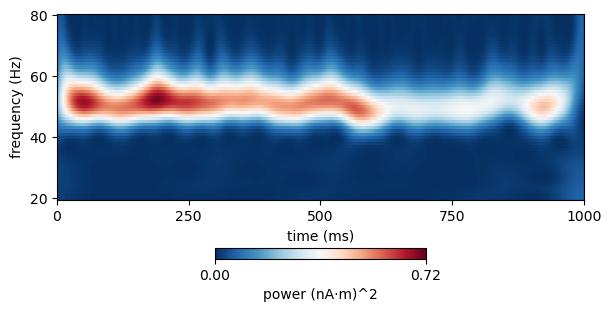

In [8]:
def plot_tfr(ax, dpl, average_trials=False, vmax_adjust=0.0, freqs=None):
    """Morlet time-frequency representation of the aggregate dipole."""
    freqs = np.arange(20, 81, 1) if freqs is None else freqs
    tfr = _compute_tfr(dpl, freqs, average_trials=average_trials)
    vmax = np.round(tfr.max() + vmax_adjust, 2)
    im = ax.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='RdBu_r',
                       vmin=0, vmax=vmax, rasterized=True)
    cb = plt.colorbar(im, ax=ax, pad=0.025, orientation='horizontal', shrink=0.4)
    cb.set_ticks([0, vmax])
    cb.set_label('power (nA\u00b7m)^2')
    ax.set_xlabel('time (ms)')
    ax.set_ylabel('frequency (Hz)')
    ax.set_yticks([20, 40, 60, 80])
    ax.set_xticks(XTICKS)
    return ax

fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
plot_tfr(ax, dpl, average_trials=True, vmax_adjust=0.02)

<Axes: xlabel='frequency (Hz)'>

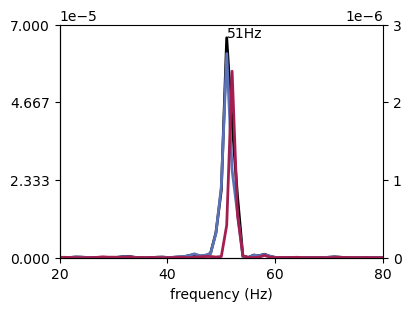

In [9]:
def plot_psd(ax, dpl):
    """Periodogram of the aggregate (black) and L5 (blue) dipole; L2 (red) on a twin axis."""
    freqs, Pxx = periodogram(dpl[0].data['agg'], dpl[0].sfreq, window='hamming',
                             nfft=len(dpl[0].data['agg']))
    _, PxxL2 = periodogram(dpl[0].data['L2'], dpl[0].sfreq, window='hamming',
                           nfft=len(dpl[0].data['L2']))
    _, PxxL5 = periodogram(dpl[0].data['L5'], dpl[0].sfreq, window='hamming',
                           nfft=len(dpl[0].data['L5']))
    ax_tw = ax.twinx()
    ax_tw.plot(freqs, PxxL2, color=np.array([164, 30, 79]) / 255, linewidth=2)
    ax.plot(freqs, Pxx, color='k', linewidth=2)
    ax.plot(freqs, PxxL5, color=np.array([92, 114, 183]) / 255, linewidth=2)
    ax.text(freqs[np.argmax(Pxx)], np.max(Pxx), f'{np.round(freqs[np.argmax(Pxx)]):.0f}Hz')
    ax.set_xlim([20, 80])
    ax.set_xticks([20, 40, 60, 80])
    ax.set_xlabel('frequency (Hz)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    upper, ticks = _nice_ylim(Pxx.max())
    ax.set_ylim([0, upper]); ax.set_yticks(ticks)
    upper_l2, ticks_l2 = _nice_ylim(PxxL2.max())
    ax_tw.set_ylim([0, upper_l2]); ax_tw.set_yticks(ticks_l2)
    return ax

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
plot_psd(ax, dpl)

Text(0.5, 1.0, 'L5')

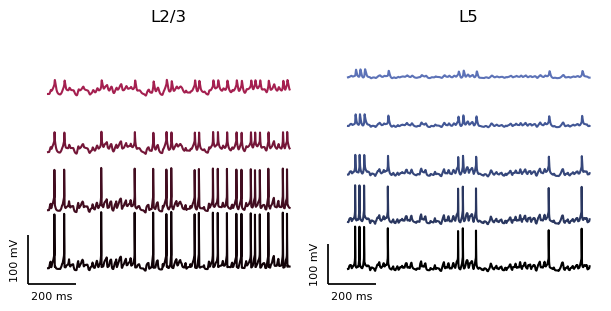

In [10]:
def plot_vsec(ax, net, cell_type, offset=120):
    """Membrane potential along the apical dendrite of the most-active cell (scale bar, fixed ylim)."""
    sections, colors = SECTIONS[cell_type], SECTION_COLORS[cell_type]
    gid = _example_gid(net, cell_type)
    for i, section in enumerate(sections):
        v = np.array(net.cell_response.vsec[0][gid][section])
        ax.plot(net.cell_response.times, v + i * offset, color=colors[i], linewidth=1.5)
    # fixed ylim: add_scalebar sizes the bar as a fraction of the current ylim
    ax.set_ylim([-90, (len(sections) - 1) * offset + 60])
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    add_scalebar(ax, x_len=200, y_len=100, x_label='200 ms', y_label='100 mV')
    return ax

fig, axes = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)
plot_vsec(axes[0], net, 'L2_pyramidal'); axes[0].set_title('L2/3')
plot_vsec(axes[1], net, 'L5_pyramidal'); axes[1].set_title('L5')

Text(0.5, 1.0, 'L5')

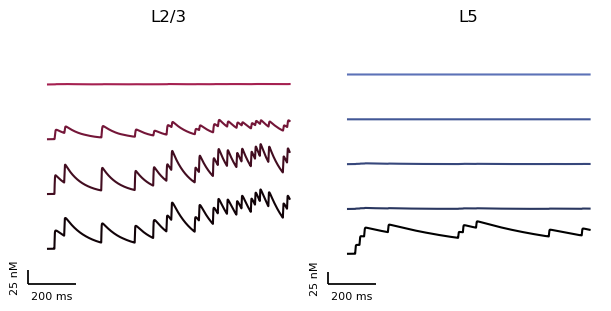

In [11]:
def plot_ca(ax, net, cell_type, offset=1e-4):
    """Calcium concentration along the apical dendrite of the most-active cell (scale bar, fixed ylim)."""
    sections, colors = SECTIONS[cell_type], SECTION_COLORS[cell_type]
    gid = _example_gid(net, cell_type)
    for i, section in enumerate(sections):
        c = np.array(net.cell_response.ca[0][gid][section])
        ax.plot(net.cell_response.times, c + i * offset, color=colors[i], linewidth=1.5)
    ax.set_ylim([0, (len(sections) - 1) * offset + 1.5e-4])
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    add_scalebar(ax, x_len=200, y_len=2.5e-5, x_label='200 ms', y_label='25 nM')
    return ax

fig, axes = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)
plot_ca(axes[0], net, 'L2_pyramidal'); axes[0].set_title('L2/3')
plot_ca(axes[1], net, 'L5_pyramidal'); axes[1].set_title('L5')

## Composite figures

In [12]:
def plot_single_trial_sim(net, dpl):
    """Single-trial composite: drives, dipole, raster+dipoles, TFR, PSD, membrane potential and calcium."""
    fig = plt.figure(figsize=(20, 8))
    gs = fig.add_gridspec(5, 7, height_ratios=[.25, .25, .25, .25, 1.25], hspace=0.5, wspace=0.6)

    axempty = fig.add_subplot(gs[1:4, :1]); axempty.set_axis_off()
    ax_drive = fig.add_subplot(gs[0, 1:3])
    ax_dpl = fig.add_subplot(gs[1:4, 1:3])
    ax_raster = fig.add_subplot(gs[0:4, 3:5])     # merged L2/3 + L5 raster
    ax_tfr = fig.add_subplot(gs[:4, 5:])
    ax_psd = fig.add_subplot(gs[4, :2])
    ax_v23 = fig.add_subplot(gs[4, 2]); ax_ca23 = fig.add_subplot(gs[4, 3])
    ax_v5 = fig.add_subplot(gs[4, 4]); ax_ca5 = fig.add_subplot(gs[4, 5])

    plot_drive_hist(ax_drive, net)
    plot_dipole(ax_dpl, dpl)
    plot_raster(ax_raster, net, dpl)
    plot_tfr(ax_tfr, dpl, average_trials=True, vmax_adjust=0.02)
    plot_psd(ax_psd, dpl)
    plot_vsec(ax_v23, net, 'L2_pyramidal'); plot_ca(ax_ca23, net, 'L2_pyramidal')
    plot_vsec(ax_v5, net, 'L5_pyramidal'); plot_ca(ax_ca5, net, 'L5_pyramidal')
    return fig

In [13]:
def plot_multi_trial_sim(net, dpl):
    """Multi-trial composite: drives, dipole, raster+dipoles, single-trial TFR and trial-averaged TFR."""
    fig = plt.figure(constrained_layout=True, figsize=(20, 4))
    gs = fig.add_gridspec(4, 4, height_ratios=[.25, .25, .25, .25], hspace=0.3, wspace=.4)

    ax_drive = fig.add_subplot(gs[0, 0])
    ax_dpl = fig.add_subplot(gs[1:4, 0])
    ax_raster = fig.add_subplot(gs[:, 1])          # merged L2/3 + L5 raster
    
    ax_tfr1 = fig.add_subplot(gs[:, 2])
    ax_tfr_avg = fig.add_subplot(gs[:, 3])

    plot_drive_hist(ax_drive, net, trial_idx=0)
    plot_dipole(ax_dpl, dpl)
    plot_raster(ax_raster, net, dpl, trial_idx=0)
    plot_tfr(ax_tfr1, dpl, average_trials=False)
    plot_tfr(ax_tfr_avg, dpl, average_trials=True, vmax_adjust=-0.03)
    return fig

### Composite — Fig. 11b–g

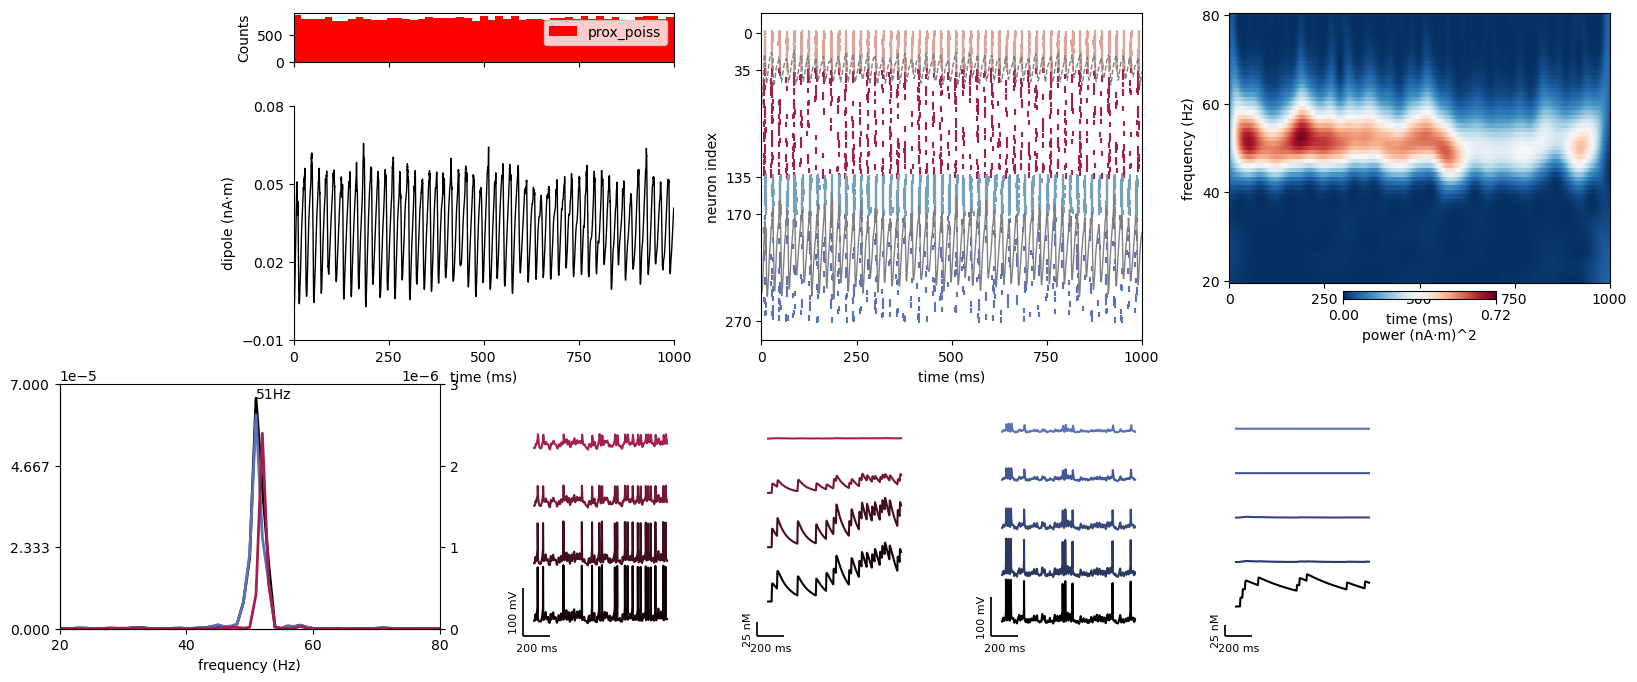

In [14]:
fig = plot_single_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_sustained.png'))
fig.savefig(op.join(pathfig, 'gamma_ET_model_sustained.pdf'))

## Fig. 11h–k — bursty gamma

Reduced inhibition, lower drive rate (100 Hz) and NMDA weight; 100 trials.

The simulation is run separately by `step1_gamma_burst_simulation.py` (on the cluster via
`step1_gamma_burst_simulation.sh`), which writes `net_gamma_bursty.pkl` / `dpl_gamma_bursty.pkl`
to `sim_results/`. Here we load the files and plot with `plot_multi_trial_sim`.

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_13896/47178596.py:13: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.png'))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_13896/47178596.py:14: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes s

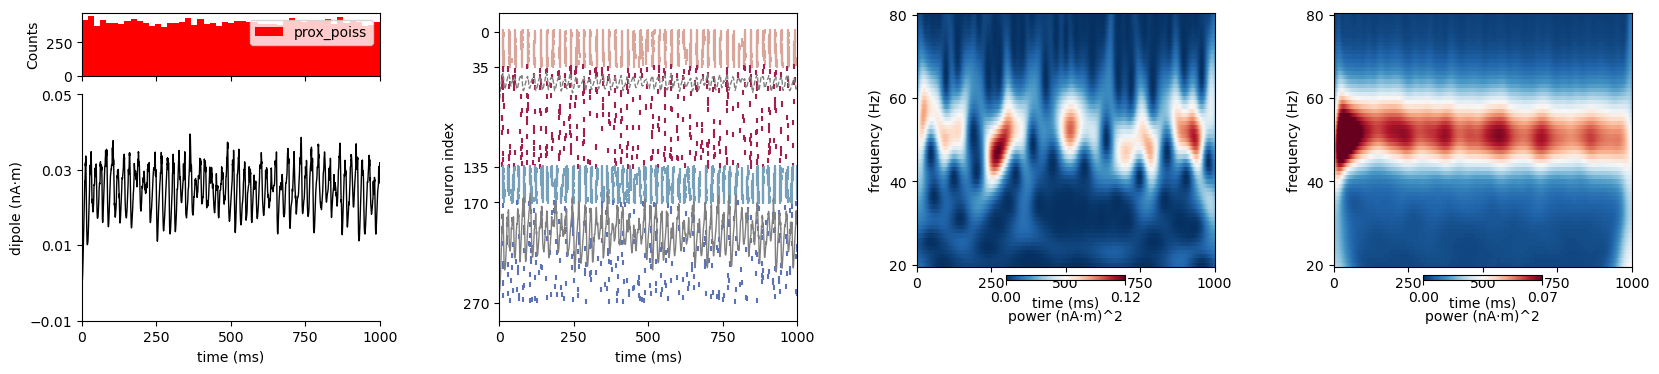

In [ ]:
# the 100-trial simulation is run separately (cluster):
#     python step1_gamma_burst_simulation.py --n_trials 100 --n_procs 50
# here we just load its output and plot
import pickle

out_pth = op.join(RESULTS, 'network_sim', 'gamma')
with open(op.join(out_pth, 'net_gamma_bursty.pkl'), 'rb') as f:
    net = pickle.load(f)
with open(op.join(out_pth, 'dpl_gamma_bursty.pkl'), 'rb') as f:
    dpl = pickle.load(f)

fig = plot_multi_trial_sim(net, dpl)
fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.png'))
fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))

In [16]:
del net, dpl

## Supp. Fig. 4 — Poisson drive to the `duecker_ET_model`

The untuned `duecker_ET_model` (default parameters) driven by the same proximal Poisson drive.

In [ ]:
# Exploratory: duecker ET model in response to gamma drive

net = duecker_ET_model()
weights_ampa = {'L2_pyramidal': 0.0035, 'L5_pyramidal': 0.0055}
weights_nmda = {'L2_pyramidal': 0.0025, 'L5_pyramidal': 0.0035}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}              # reduce frequency, make noisier

net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

#with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):

dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1, record_vsec='all', record_ca='all')



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Trial 1: 360.0 ms...
Trial 1: 370.0 ms...
Trial 1: 380.0 ms...
Trial 1: 390.0 ms...
Trial 1: 400.0 ms...
Trial 1: 410.0 ms...
Trial 1: 420.0 ms...

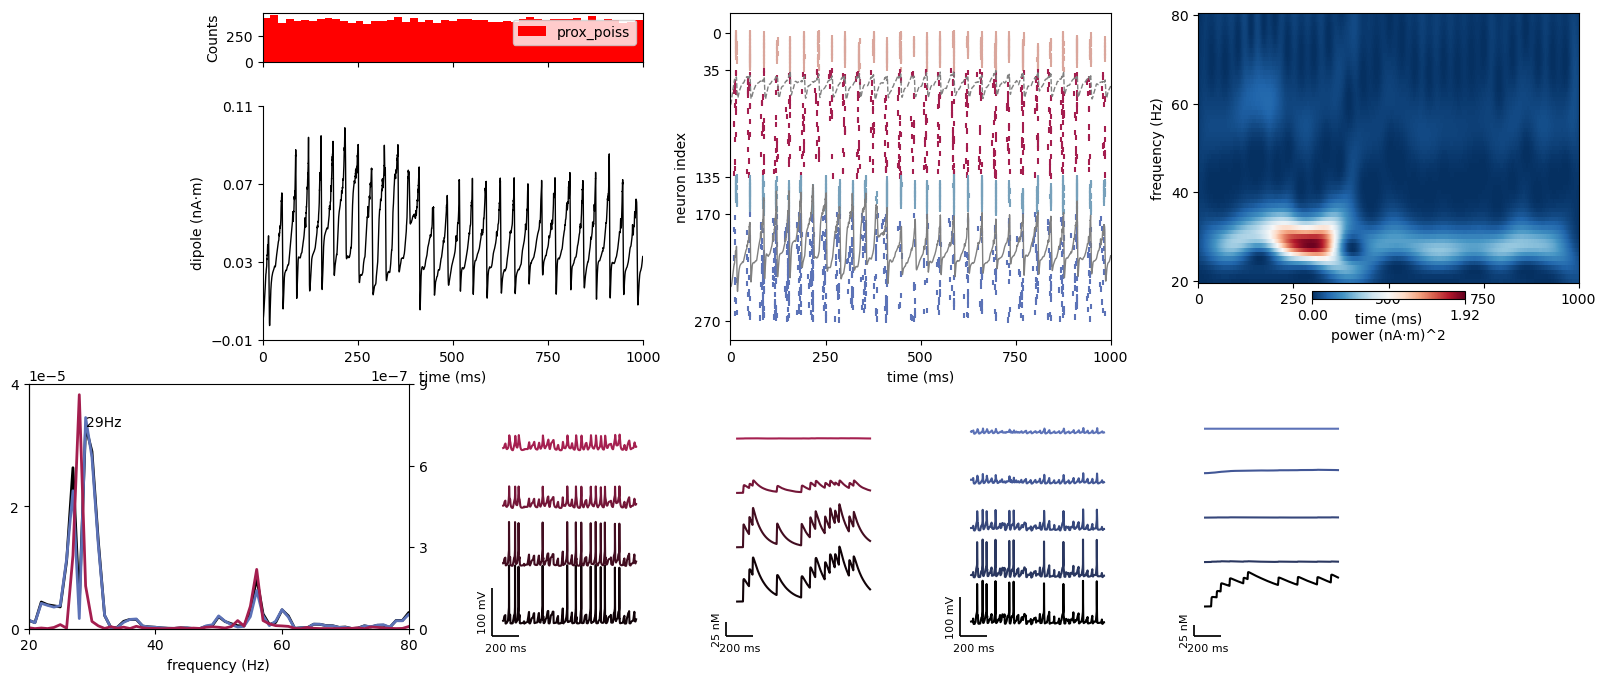

In [18]:
fig = plot_single_trial_sim(net, dpl)
fig.savefig(op.join(pathfig, 'gamma_drive_dueckerET_model.png'))
fig.savefig(op.join(pathfig, 'gamma_drive_dueckerET_model.pdf'))

## Laminar LFP and CSD - not in paper

Re-run a single trial with a laminar electrode array and compute the current-source density (CSD) alongside the LFP traces.